# MP2: Control task in a continuous environment

In [ ]:
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd

from environments.acrobot_gym import Acrobot

In [2]:
env = Acrobot()

<frozen importlib._bootstrap>:241: RuntimeWarning: Your system is avx2 capable but pygame was not built with support for it. The performance of some of your blits could be adversely affected. Consider enabling compile time detection with environment variables like PYGAME_DETECT_AVX2=1 if you are compiling without cross compilation.


## Simulation and plotting functions

In [37]:
class AbstractAgent:
    """
    Abstract base class for agents interacting with the FrozenLake environment.
    Each agent must implement the `observe` method to update its internal state based on the observed transition,
    and the `act` method to choose an action given the current state.
    """
    def __init__(self, env: Acrobot):
        self.env = env

    def observe(self, state, action, reward, next_state, done):
        raise NotImplementedError

    def act(self, state):
        raise NotImplementedError
    

def run_agent(env: Acrobot, agent: AbstractAgent, num_episodes: int, print_every: int = 10):
    """
    Run the given agent in the environment for a specified number of episodes and collect statistics.
    """
    rewards = []
    episode_length = []
    for episode in range(num_episodes):
        state = env.reset()
        done = False
        steps = 0
        episode_reward = 0
        while not done:
            action = agent.act(state) # TODO
            next_state, reward = env.do_action(action)
            done = env.end
            steps += 1
            # TODO: update agent with the observed transition
            agent.observe(state, action, reward, next_state, done)
            state = next_state
            episode_reward += reward
        # TODO: log rewards and episode length
        if episode % print_every == 0:
            print(f"reward ({episode}) - {episode_reward}")
            print(f"steps ({episode}) - {steps}")

        rewards.append(episode_reward)
        episode_length.append(steps)
        
        
    return rewards, episode_length

def gif_episode(env: Acrobot, agent: AbstractAgent, filename: str = "episode.gif"):
    """
    Run a single episode with the given agent and save the frames as a GIF.
    """
    state = env.reset()
    done = False
    while not done:
        action = agent.act(state)
        next_state, reward = env.do_action(action)
        done = env.end
        # no observe step for the agent
        state = next_state
    env.save_gif(filename)

def plot_rewards(rewards, window_size=10):
    
    series = pd.Series(rewards)
    moving_avg = series.rolling(window=window_size).mean()
    
    plt.figure(figsize=(10, 6))
    plt.plot(series, label='Original Data', marker='o', linestyle='--', alpha=0.6, color='royalblue')

    plt.plot(moving_avg, label=f'Moving Average (Window {window_size})', linewidth=3, color='crimson')

    plt.title('Data Smoothing via Moving Average', fontsize=14)
    plt.xlabel('Index', fontsize=12)
    plt.ylabel('Value', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)

    plt.show()
    

def plot_success(rewards, window_size=10):
    """
    Plot binary success and moving success rate.

    success_threshold:
        Episode is counted as success if total reward >= success_threshold.
        Adjust depending on how your Acrobot reward is defined.
    """
    successes = [1 if r > -500 else 0 for r in rewards]

    series = pd.Series(successes)
    moving_avg = series.rolling(window=window_size).mean()

    plt.figure(figsize=(10, 6))
    plt.plot(series, label='Success (0/1)', marker='o', linestyle='--', alpha=0.5)
    plt.plot(moving_avg, label=f'Success Rate (Window {window_size})', linewidth=3)

    plt.title('Episode Success Rate')
    plt.xlabel('Episode')
    plt.ylabel('Success')
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

# additional functions can be added here
# ...

## Part 2: TD Learning

### Part 2.1: Random agent

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. How often does the random agent reach the target height?
2. What is the average reward collected by the random agent? Interpret this value in terms of episode duration.

**Your answers here**
1. ...
2. ...

In [4]:
import random

In [10]:
# Random agent
class RandomAgent(AbstractAgent):
    def observe(self, state, action, reward, next_state, done):
        pass  
    
    def act(self, state):
        # TODO: implement a random agent that selects actions uniformly at random
        return random.choice(env.available()) # [0, 1, 2]

random_ag = RandomAgent(env)

gif_episode(env, random_ag, filename="random_agent_episode.gif")

reward (0) - -500.0
steps (0) - 500
reward (10) - -500.0
steps (10) - 500
reward (20) - -500.0
steps (20) - 500
reward (30) - -500.0
steps (30) - 500
reward (40) - -500.0
steps (40) - 500
reward (50) - -500.0
steps (50) - 500
reward (60) - -500.0
steps (60) - 500
reward (70) - -500.0
steps (70) - 500
reward (80) - -500.0
steps (80) - 500
reward (90) - -500.0
steps (90) - 500


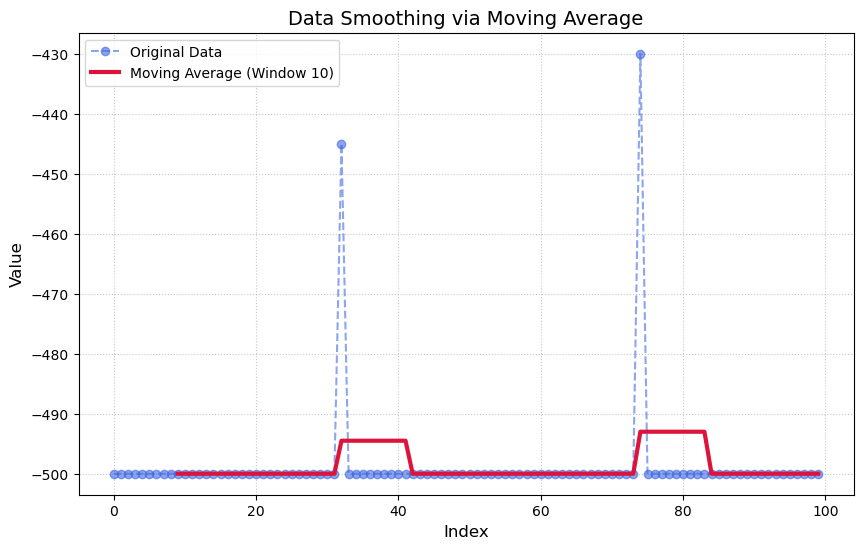

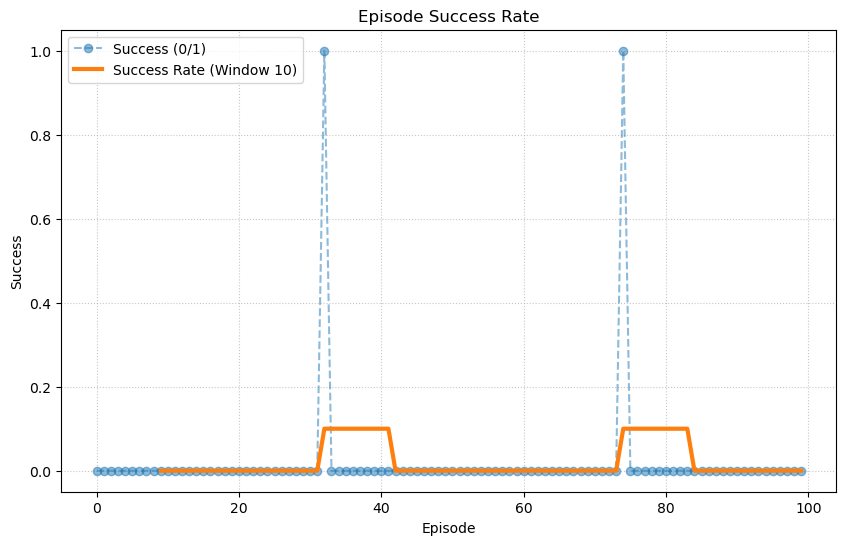

In [38]:
random_rewards, random_episode_lengths = run_agent(env, random_ag, num_episodes=100, print_every=10)
plot_rewards(random_rewards)
plot_success(random_rewards)


In [43]:
print(np.mean(random_rewards))
print(np.mean(random_episode_lengths))

-498.75
498.77


### Part 2.2: Q-Learning with state discretization

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. For a given number of bins per dimension $n$, how many discrete states are there in total? How does this scale with the state dimension $d$?
2. What are the trade-offs of using a small number of bins? What are the trade-offs of using a large number of bins?
3. On average, which agent (random or Q-learning) will first reach the target height? Would this change with a different value of $\varepsilon$, a different Q-value initialization or a different reward function? Justify.
4. Does the Q-learning agent improve its performance over time? Does it manage to reach the goal in every episode eventually? Why or why not?
5. How does performance depend on n_bins? Which value gives the best results on this environment?

**Your answers here**
1. ...
2. ...
3. ...
4. ...
5. ...

In [ ]:
class StateDiscretizer:
    def __init__(self, env, n_bins):
        self.lower_bound, self.upper_bound = env.state_space
        self.n_bins = n_bins
        # your code here
    
    def __call__(self, state):
        # your code here
        raise NotImplementedError

# test the discretizer
state = env.reset()
discretizer = StateDiscretizer(env, n_bins=10)
discretized_state = discretizer(state)
print("Original state:", state)
print("Discretized state:", discretized_state)

In [ ]:
class QLearningAgent(AbstractAgent):
    def __init__(self, env, alpha=0.1, gamma=0.99, epsilon=0.1, n_bins=10):
        super().__init__(env)
        self.discretizer = StateDiscretizer(env, n_bins)
        self.Q = defaultdict(lambda: np.zeros(self.n_actions)) # you can use a different data structure if you prefer
        # your code here

    def observe(self, state, action, reward, next_state, done):
        # your code here
        raise NotImplementedError

    def act(self, state):
        # your code here
        raise NotImplementedError
    
# Analyze the Q-learning agent
# ...

### Part 2.3: Q-Learning with state discretization

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. Derive the partial derivative of $\mathcal{L}(w) = \frac{1}{2}\delta^2$ with respect to $w_{a,j}$, treating the target as a constant. Show your calculations and state the resulting update rule.
2. After observing a transition $(s_t,a_t,r_t,s_{t+1})$, which of the weights $w_{a,j}$ get updated and which stay unchanged?
3. What would differ between the bin-based Q-learning agent and the RBF agent in their treatment of a previously unseen state?
4. Does the RBF agent improve over time? Does it reach the goal consistently? Why or why not?
5. How does performance depend on n_centers_per_dim and $\alpha$? Which combination yields the best results?

**Your answers here**
1. ...
2. ...
3. ...
4. ...
5. ...

In [ ]:
def rbf_features(state, centers, sigma):
    """
    Compute the RBF features for a given state, given the centers and sigma.
    Arguments:
        - state: the input state, a vector of shape (state_dim,)
        - centers: a np array of shape (n_centers, state_dim)
        - sigma: a vector of shape (state_dim,)
    """
    # your code here
    raise NotImplementedError

class RBFAgent(AbstractAgent):
    """
    Agent using Radial Basis Function (RBF) features to approximate the Q-function.
    """
    def __init__(self, env: Acrobot, alpha: float = 0.1, gamma: float = 0.9, epsilon_exploration: float = 0.1, n_centers_per_dim: int = 5):
        super().__init__(env)
        # your code here
        self.centers = ...
        self.sigmas = ...
        self.Q_weights = ...

    def observe(self, state: int, action: int, reward: float, next_state: int, done: bool):
        # your code here
        raise NotImplementedError

    def act(self, state: int) -> int:
        # your code here
        raise NotImplementedError
    
# Analyze the RBF agent
# ...

## Part 3: Policy gradient

### part 3.1: REINFORCE with a linear softmax policy

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. What gradient expression did you derive? Show your calculations.
2. What are the main differences between REINFORCE and Q-learning with RBFs in terms of (i) what they learn, (ii) how they update, and (iii) the kind of policy they produce?
3. Could we use an $\varepsilon$-greedy policy with REINFORCE? Why or why not?
4. Does the agent improve over time? Comment on your plots.

**Your answers here**
1. ...
2. ...
3. ...
4. ...

In [ ]:
class REINFORCEAgent(AbstractAgent):
    def __init__(self, env: Acrobot, alpha: float = 0.1, gamma: float = 0.9, n_centers_per_dim: int = 5):
        super().__init__(env)
        # your code here
        self.centers = ...
        self.sigmas = ...
        self.policy_weights = ...
        self.episode_memory = []  # to store (state, action, reward) for the current episode


    def observe(self, state: int, action: int, reward: float, next_state: int, done: bool):
        # your code here
        raise NotImplementedError

    def act(self, state: int) -> int:
        # your code here
        raise NotImplementedError

# Analyze the REINFORCE agent
# ...

### part 3.2: REINFORCE with a Multi-Layer Perceptron (MLP)

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. Compared to the linear softmax policy, what has changed architecturally, and why does this make the policy more expressive?
2. Compare the performance of linear and MLP REINFORCE agents. Is there a significant improvement?
3. For which value of the learning rate do you find the best results?

**Your answers here**
1. ...
2. ...
3. ...

In [ ]:
# use pytorch to implement a MLP policy network and train it with REINFORCE
class REINFORCEAgentMLP(AbstractAgent):
    def __init__(self, env: Acrobot, alpha: float = 0.1, gamma: float = 0.9, hidden_size: int = 64):
        super().__init__(env)
        
        # your code here

        self.n_actions = env.n_actions
        self.state_dim = env.state_dim
        # simple MLP with one hidden layer
        self.policy_mlp = torch.nn.Sequential(
            torch.nn.Linear(self.state_dim, hidden_size),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_size, self.n_actions)
        )
        self.optimizer = torch.optim.Adam(self.policy_mlp.parameters(), lr=self.alpha)
        self.episode_memory = []  # to store (state, action, reward) for the current episode

    def _compute_probs(self, state):
        """
        
        """
        state_tensor = torch.FloatTensor(state)
        logits = self.policy_mlp(state_tensor)
        exp_logits = torch.exp(logits - torch.max(logits))  # for numerical stability
        probs = exp_logits / (torch.sum(exp_logits) + 1e-8)  # add small value to avoid division by zero
        return probs
    
    def _compute_loss_term(self, state, action, G):
        probs = self._compute_probs(state)
        log_prob = torch.log(probs[action])
        return -log_prob * G
    
    def _update_parameters(self, sum_of_loss_terms):
        self.optimizer.zero_grad()
        sum_of_loss_terms.backward()
        self.optimizer.step()
    

    def act(self, state):
        # your code here (use _compute_probs)
        raise NotImplementedError

    
    def observe(self, state, action, reward, next_state, done):
        # your code here
        # hint: compute G for each loss term, then use _compute_loss_term and _update_parameters
        raise NotImplementedError



## part 4: Actor-Critic

Complete the tasks described in the project description and answer the following questions:

**Questions:**
1. 
2. 
3. 

**Your answers here**
1. ...
2. ...
3. ...

In [ ]:
class ActorCriticAgent(AbstractAgent):
    def __init__(self, env: Acrobot, alpha_actor: float = 0.1, alpha_critic: float = 0.1, gamma: float = 0.9, hidden_size: int = 64):
        super().__init__(env)
        # your code here

        self.n_actions = env.n_actions
        self.state_dim = env.state_dim
        # simple MLP for the policy (actor)
        self.policy_mlp = torch.nn.Sequential(
            torch.nn.Linear(self.state_dim, hidden_size),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_size, self.n_actions)
        )
        # simple MLP for the value function (critic)
        self.value_mlp = torch.nn.Sequential(
            torch.nn.Linear(self.state_dim, hidden_size),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_size, 1)
        )
        self.optimizer_actor = torch.optim.Adam(self.policy_mlp.parameters(), lr=alpha_actor)
        self.optimizer_critic = torch.optim.Adam(self.value_mlp.parameters(), lr=alpha_critic)
        self.episode_memory = []  # to store (state, action, reward) for the current episode


    def _compute_probs(self, state):
        state_tensor = torch.FloatTensor(state)
        logits = self.policy_mlp(state_tensor)
        exp_logits = torch.exp(logits - torch.max(logits))  # for numerical stability
        probs = exp_logits / torch.sum(exp_logits) + 1e-8  # add small value to avoid division by zero
        return probs
    
    def _compute_value(self, state):
        state_tensor = torch.FloatTensor(state)
        value = self.value_mlp(state_tensor)
        return value.squeeze()  # remove extra dimension
    
    def _compute_advantage(self, state, reward, next_state, done):
        # your code here (compute advantage using the critic)
        # hint: use _compute_value
        raise NotImplementedError
    
    def _compute_actor_loss(self, state, action, reward, next_state, done):
        with torch.no_grad():
            advantage = self._compute_advantage(state, reward, next_state, done)
        probs = self._compute_probs(state)
        log_prob = torch.log(probs[action])

        return -log_prob * advantage
    
    def _compute_critic_loss(self, state, reward, next_state, done):
        advantage = self._compute_advantage(state, reward, next_state, done)
        return advantage.pow(2)  # MSE loss for the critic
    
    def _update_parameters(self, actor_loss, critic_loss):
        # update actor
        self.optimizer_actor.zero_grad()
        actor_loss.backward()
        self.optimizer_actor.step()
        # update critic
        self.optimizer_critic.zero_grad()
        critic_loss.backward()
        self.optimizer_critic.step()

    def act(self, state):
        # your code here (use _compute_probs)
        raise NotImplementedError
    
    def observe(self, state, action, reward, next_state, done):
        # your code here
        # hint: compute advantage, then compute actor and critic loss, then update parameters
        raise NotImplementedError
